# CivicFlux — Reproducible Flood Scenario Classification

**Real rainfall reference + explicitly synthetic drainage scenarios**

A research surrogate for a documented mass-balance simulator. This notebook does not claim observed flood-event prediction or infrastructure-failure detection.

## 01. Problem definition

Given a specified 24-hour storm scenario and hypothetical catchment/drainage parameters, estimate the probability that the simulator produces peak ponding depth ≥0.15 m. The threshold is a project assumption. Rainfall is a supplied scenario input, not an observed future predictor available to a live forecaster. For a real forecast, supply an external rainfall forecast and propagate its uncertainty; errors from that upstream model are not validated here.

The target is **simulated flood occurrence**, not generic FloodProbability, a verified incident, or infrastructure failure. No supplied dataset has verified pipe-failure labels. The simulator provides the authoritative deterministic answer; ML is an approximation whose accuracy does not validate the physics.

### 1.1 Reproducibility

All parameter ranges, seeds and equations are visible.

In [1]:
from pathlib import Path
import sys, json, platform, importlib.metadata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import cross_validate, RandomizedSearchCV
from sklearn.inspection import permutation_importance
import joblib
ROOT = Path.cwd() if (Path.cwd() / 'civicflux_core.py').exists() else Path.cwd().parent
assert (ROOT / 'civicflux_core.py').exists(), 'Run from civicflux_ml or its notebooks directory'
sys.path.insert(0, str(ROOT))
from civicflux_core import *
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (11, 4), 'figure.dpi': 110})
SEED = 42
N_SPLITS = 3  # Expanding time folds; increase to five for a longer study.
N_SEARCH = 6  # Real searches are run; increase to 20+ for a larger compute budget.

OUT=ROOT/'artifacts'/'flood'
OUT.mkdir(parents=True,exist_ok=True)

## 02. Dataset introduction

Use the same downloaded [India daily rainfall](https://www.kaggle.com/datasets/wydoinn/daily-rainfall-data-india-2009-2024) reference as notebook 01. Four hypothetical drainage configurations are generated for each observed Delhi state-day. No resampling of a test-derived rainfall distribution occurs. Date groups stay together during splitting. State-average daily rainfall cannot establish local storm intensity: duration and spatial concentration are explicitly synthetic assumptions.

The [Playground flood score](https://www.kaggle.com/competitions/playground-series-s4e5/data) and [UrbanFloodBench](https://www.kaggle.com/competitions/urban-flood-modelling/data) are documented alternatives, not silently substituted training sources. See DATASET_GUIDE.md. This choice avoids presenting synthetic generic scores as observed flood incidents.

### 2.1 Load and inspect real rainfall reference

The complete original file is inspected before selecting Delhi.

In [2]:
cfg=CONFIGS['rainfall'].copy()
source_path=ROOT/'data'/'raw'/cfg['file']
raw=pd.read_csv(source_path)
fingerprint=sha256(source_path)
print('Shape',raw.shape,'SHA256',fingerprint)
display(raw.head());display(raw.dtypes)

Shape (204876, 8) SHA256 4891c75a9a0ccd2e7f75c9aafa3de110cf9a38602e0798f2a88e1895f4031611


,id,date,state_code,state_name,actual,rfs,normal,deviation
0,0,2009-01-01,5,Uttarakhand,0.0,0.003906,2.19,-100.0
1,1,2009-01-01,18,Assam,0.0,0.000000,0.52,-100.0
2,2,2009-01-01,16,Tripura,0.0,0.000000,0.09,-100.0
3,3,2009-01-01,36,Telangana,0.0,0.000000,0.17,-100.0
4,4,2009-01-01,2,Himachal Pradesh,0.0,0.008566,3.31,-100.0


id              int64
date           object
state_code      int64
state_name     object
actual        float64
rfs           float64
normal        float64
deviation     float64
dtype: object

### 2.2 Select geography and report availability

Missing rainfall is excluded from scenario forcing, not treated as dry weather.

In [3]:
history,rain_audit=canonicalize(raw,cfg)
display(pd.Series(rain_audit))
print('Reference interval',history.time.min(),history.time.max())
print('Valid real rainfall observations',history.value.notna().sum())

raw_rows                      204876
exact_duplicates_removed           0
invalid_timestamp_rows             0
negative_values_to_missing         0
selected_rows_before_grid       5691
regular_grid_rows               5691
unavailable_values               170
dtype: int64

Reference interval 2009-01-01 00:00:00+05:30 2024-07-31 00:00:00+05:30
Valid real rainfall observations 5521


### 2.3 Simulator equations and limits

Let P be daily rainfall in mm, C a dimensionless effective runoff coefficient, D storm duration in hours, q drainage capacity in mm/hour over the catchment, b blockage fraction, S₀ initial equivalent storage in mm, and f the fraction of catchment area over which excess water ponds.

$$R=CP,\quad Q=q(1-b)D,\quad S_{peak}=\max(S_0, S_0+R-Q,0),\quad h_{peak}=S_{peak}/(1000f).$$

For uniform storm intensity, storage rises or falls monotonically during the event, so the maximum is one of the endpoints. Catchment area A converts equivalent depths to volumes (m³ = mm × A / 1000), but cancels from the depth expression under a proportional drainage assumption. C lumps infiltration/interception losses; do not subtract infiltration again. No topographic routing, river overflow, tidal backwater, dynamic infiltration or pipe hydraulics is represented.

This is a deliberately simplified conservation-of-water model, **not EPA SWMM**. For the richer reservoir/routing framework see [EPA SWMM documentation](https://www.epa.gov/water-research/storm-water-management-model-swmm). All synthetic parameter ranges below are illustrative design choices, not fitted regional engineering constants.

### 2.4 Parameter distributions

These ranges define the synthetic population; the metrics only apply to it.

In [4]:
parameter_table=pd.DataFrame([
 ['rain_mm','observed Delhi state daily rainfall','mm'],['duration_h','Uniform(1,12)','hours'],['area_m2','Uniform(10000,100000)','m²'],['runoff_coefficient','Uniform(.3,.95)','fraction'],['drain_mm_h','Uniform(.2,8)','mm/hour over catchment'],['blockage','Uniform(0,.9)','fraction'],['ponding_fraction','Uniform(.03,.2)','fraction'],['initial_storage_mm','Uniform(0,2)','mm over catchment']
],columns=['input','distribution','unit'])
display(parameter_table)
parameter_table.to_csv(OUT/'scenario_parameters.csv',index=False)

,input,distribution,unit
0,rain_mm,observed Delhi state daily rainfall,mm
1,duration_h,"Uniform(1,12)",hours
2,area_m2,"Uniform(10000,100000)",m²
3,runoff_coefficient,"Uniform(.3,.95)",fraction
4,drain_mm_h,"Uniform(.2,8)",mm/hour over catchment
5,blockage,"Uniform(0,.9)",fraction
6,ponding_fraction,"Uniform(.03,.2)",fraction
7,initial_storage_mm,"Uniform(0,2)",mm over catchment


### 2.5 Generate a reproducible moderate-sized scenario set

Four configurations per real day preserve rainfall frequency, including dry days; one million near-duplicates would not add independent weather events.

In [5]:
scenarios=generate_scenarios(history,repeats=4,seed=SEED)
pd.testing.assert_frame_equal(scenarios,generate_scenarios(history,repeats=4,seed=SEED))
print('Scenarios:',len(scenarios),'Independent dated forcing groups:',scenarios.event_id.nunique())
scenarios.to_csv(ROOT/'data'/'flood_scenarios.csv',index=False)

Scenarios: 22084 Independent dated forcing groups: 5521


## 03. Data inspection

Inspect both the real forcing and the generated outcomes. Synthetic cleanliness is not evidence of measurement quality.

### 3.1 Head, shape and types

Date/event identifiers are audit fields, not model inputs.

In [6]:
display(scenarios.head(10));print(scenarios.shape);display(scenarios.dtypes)

,time,rain_mm,event_id,scenario_id,duration_h,area_m2,runoff_coefficient,drain_mm_h,blockage,ponding_fraction,initial_storage_mm,depth_m,target,target_time,source_quality
0,2009-01-01 00:00:00+05:30,0.0,2009-01-01 00:00:00+05:30,0,9.513517,47702.286599,0.696734,5.201264,0.359443,0.076098,1.411140,0.018544,0,2009-01-02 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...
1,2009-01-01 00:00:00+05:30,0.0,2009-01-01 00:00:00+05:30,1,5.827663,51648.425616,0.346352,3.971110,0.087967,0.082042,1.604573,0.019558,0,2009-01-02 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...
2,2009-01-01 00:00:00+05:30,0.0,2009-01-01 00:00:00+05:30,2,10.444577,39817.947608,0.754965,7.290970,0.514044,0.106788,0.818487,0.007665,0,2009-01-02 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...
3,2009-01-01 00:00:00+05:30,0.0,2009-01-01 00:00:00+05:30,3,8.671048,19759.492012,0.819358,1.234095,0.214446,0.192811,1.389360,0.007206,0,2009-01-02 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...
4,2009-01-02 00:00:00+05:30,0.0,2009-01-02 00:00:00+05:30,4,2.035951,27942.746310,0.871839,5.528883,0.083179,0.120633,1.607143,0.013323,0,2009-01-03 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...
5,2009-01-02 00:00:00+05:30,0.0,2009-01-02 00:00:00+05:30,5,11.731846,82311.980899,0.789991,4.784822,0.543476,0.196061,1.839956,0.009385,0,2009-01-03 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...
6,2009-01-02 00:00:00+05:30,0.0,2009-01-02 00:00:00+05:30,6,9.372537,68704.311901,0.629383,5.976730,0.316620,0.111875,1.950259,0.017433,0,2009-01-03 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...
7,2009-01-02 00:00:00+05:30,0.0,2009-01-02 00:00:00+05:30,7,9.646707,94855.734187,0.867979,3.852815,0.272248,0.134905,1.134708,0.008411,0,2009-01-03 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...
8,2009-01-03 00:00:00+05:30,0.0,2009-01-03 00:00:00+05:30,8,2.409250,83896.151829,0.619142,0.474378,0.818980,0.152953,1.485091,0.009709,0,2009-01-04 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...
9,2009-01-03 00:00:00+05:30,0.0,2009-01-03 00:00:00+05:30,9,5.954245,46199.820344,0.811606,3.256985,0.099209,0.069743,1.696119,0.024320,0,2009-01-04 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...


(22084, 15)


time                  datetime64[ns, Asia/Kolkata]
rain_mm                                    float64
event_id                                    object
scenario_id                                  int64
duration_h                                 float64
area_m2                                    float64
runoff_coefficient                         float64
drain_mm_h                                 float64
blockage                                   float64
ponding_fraction                           float64
initial_storage_mm                         float64
depth_m                                    float64
target                                       int64
target_time           datetime64[ns, Asia/Kolkata]
source_quality                              object
dtype: object

### 3.2 Nulls, duplicates and ranges

Scenario IDs must be unique; repeated event IDs are intentional groups.

In [7]:
display(scenarios.isna().sum());print('Duplicate scenario IDs:',scenarios.scenario_id.duplicated().sum())
display(scenarios.describe().T)
assert scenarios.scenario_id.is_unique
assert not scenarios[FLOOD_FEATURES+['target']].isna().any().any()

time                  0
rain_mm               0
event_id              0
scenario_id           0
duration_h            0
area_m2               0
runoff_coefficient    0
drain_mm_h            0
blockage              0
ponding_fraction      0
initial_storage_mm    0
depth_m               0
target                0
target_time           0
source_quality        0
dtype: int64

Duplicate scenario IDs: 0


,count,mean,std,min,25%,50%,75%,max
rain_mm,22084.0,1.626147,5.953131,0.000000e+00,0.000000,0.000000,0.050000,97.500000
scenario_id,22084.0,11041.500000,6375.246008,0.000000e+00,5520.750000,11041.500000,16562.250000,22083.000000
duration_h,22084.0,6.511826,3.178211,1.000145e+00,3.731389,6.541098,9.261353,11.999807
area_m2,22084.0,55053.043543,26006.695188,1.000247e+04,32490.497815,55228.033264,77634.413729,99996.138215
runoff_coefficient,22084.0,0.626042,0.186899,3.000086e-01,0.465563,0.626147,0.787605,0.949996
drain_mm_h,22084.0,4.102316,2.244030,2.007441e-01,2.160118,4.125081,6.013212,7.999626
blockage,22084.0,0.450702,0.260381,3.250728e-05,0.225001,0.450726,0.678621,0.899941
ponding_fraction,22084.0,0.114702,0.049006,3.000766e-02,0.072083,0.114375,0.156882,0.199992
initial_storage_mm,22084.0,0.998802,0.577924,5.160200e-05,0.496168,0.992217,1.502669,1.999651
depth_m,22084.0,0.014697,0.034748,5.538553e-07,0.004494,0.009034,0.015654,1.797252


### 3.3 Target prevalence

An imbalanced simulator calls for precision-recall metrics and per-fold class checks.

target
no simulated flood    21921
simulated flood         163
Name: count, dtype: int64

Positive prevalence: 0.007380909255569643


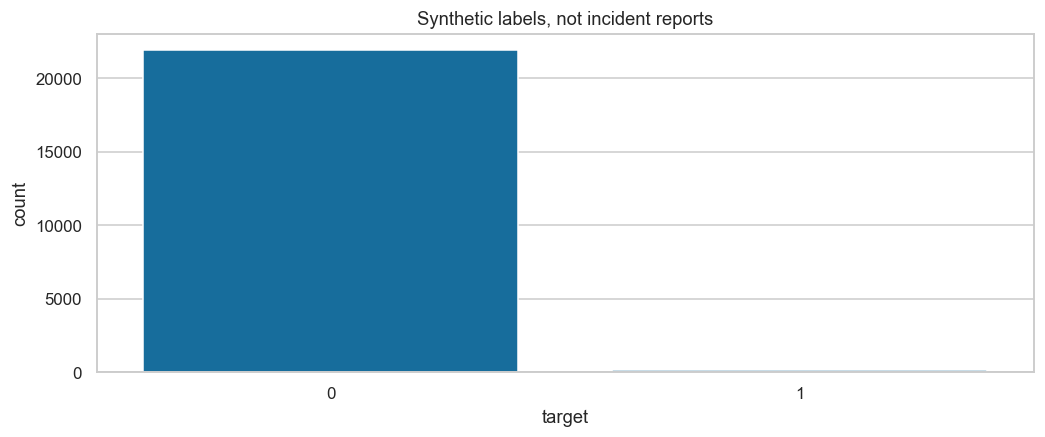

In [8]:
display(scenarios.target.value_counts().rename({0:'no simulated flood',1:'simulated flood'}))
print('Positive prevalence:',scenarios.target.mean())
sns.countplot(data=scenarios,x='target');plt.title('Synthetic labels, not incident reports');plt.show()

### 3.4 Reference rainfall missingness

The scenario set omits missing forcing; report that selection effect.

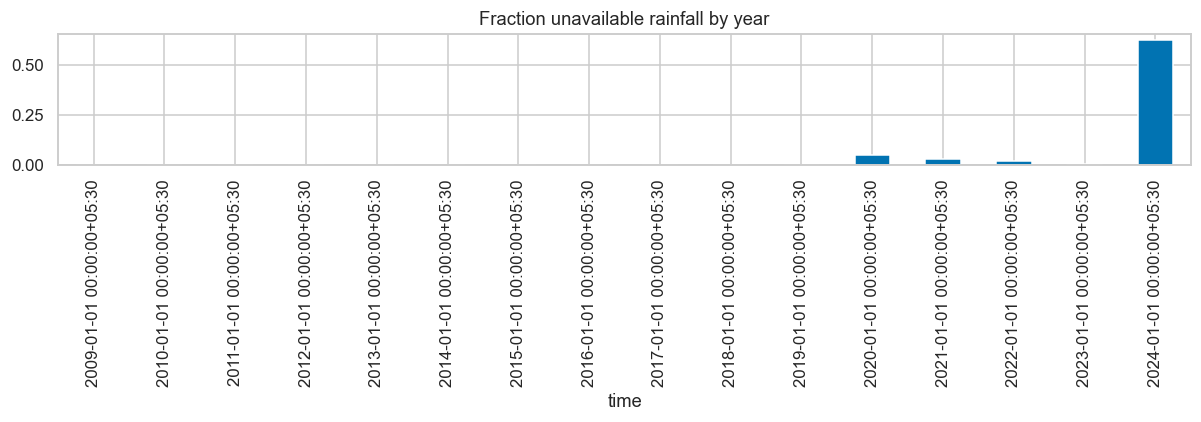

In [9]:
history.set_index('time').value.isna().resample('YS').mean().plot.bar(title='Fraction unavailable rainfall by year')
plt.tight_layout();plt.show()

## 04. Exploratory analysis

EDA uses the development period only. Labels describe the simulator; relations can reflect its equations by construction.

In [10]:
dev,cal,test=partition(scenarios)
eda=dev.copy()
print("Development scenario count",len(eda))

Development scenario count 13244


### 4.1 Real rainfall distribution and synthetic depth

Dry days dominate many rainfall series, while concentrating water into a small ponded area creates a long depth tail.

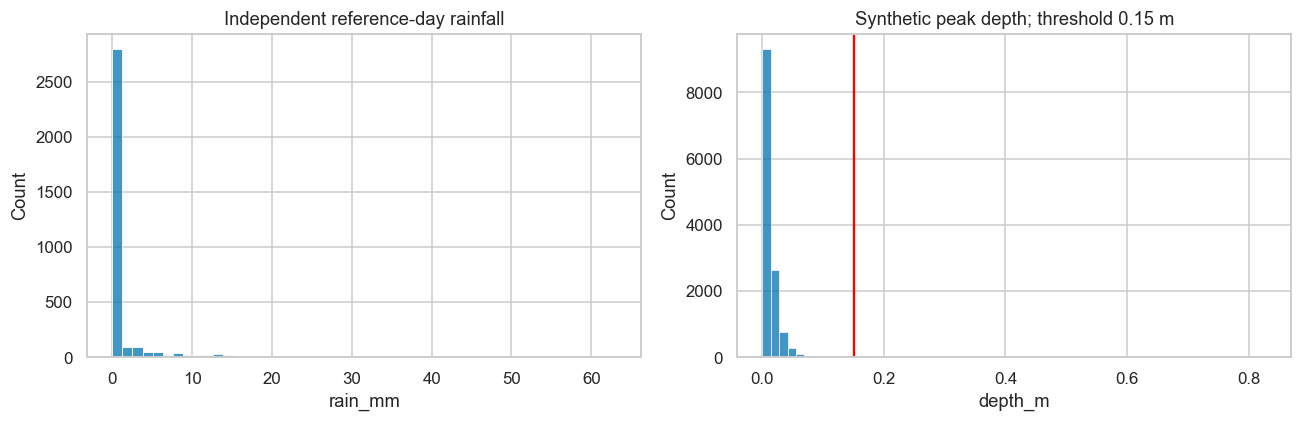

In [11]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(eda.drop_duplicates('event_id').rain_mm,bins=50,ax=ax[0]);ax[0].set_title('Independent reference-day rainfall')
sns.histplot(eda.depth_m,bins=60,ax=ax[1]);ax[1].axvline(.15,color='red');ax[1].set_title('Synthetic peak depth; threshold 0.15 m')
plt.tight_layout();plt.show()

### 4.2 Seasonal event rate

The rate is conditional on synthetic asset ranges and must not be called observed flood frequency.

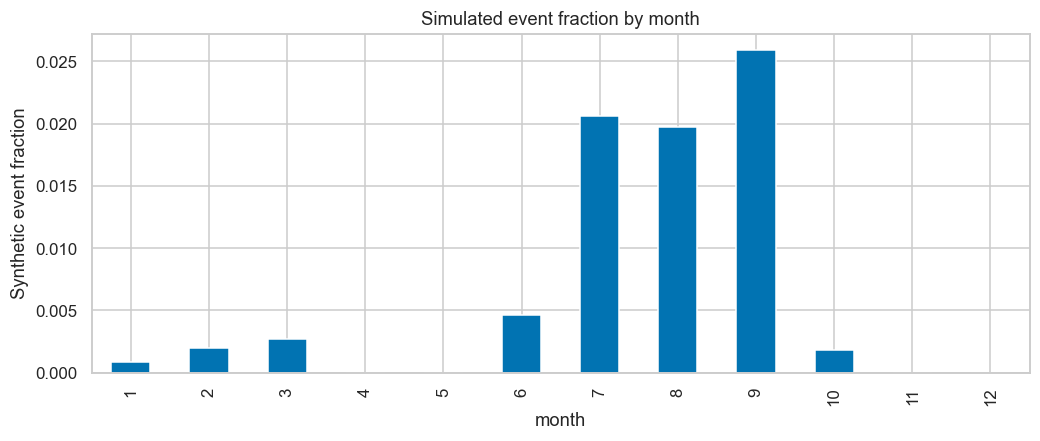

In [12]:
eda.assign(month=eda.time.dt.month).groupby('month').target.mean().plot.bar(title='Simulated event fraction by month',ylabel='Synthetic event fraction');plt.show()

### 4.3 Drainage and blockage relationships

Plot sampled design parameters against label to inspect simulator behavior.

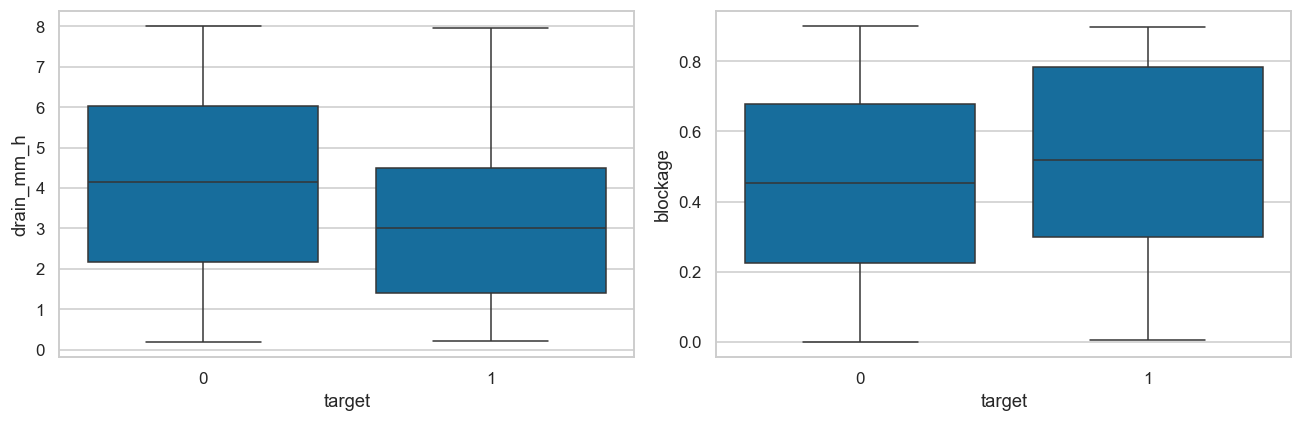

In [13]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.boxplot(data=eda,x='target',y='drain_mm_h',ax=ax[0])
sns.boxplot(data=eda,x='target',y='blockage',ax=ax[1])
plt.tight_layout();plt.show()

### 4.4 Rainfall-depth response

Multiple depths for the same rain amount reflect differing hypothetical catchments.

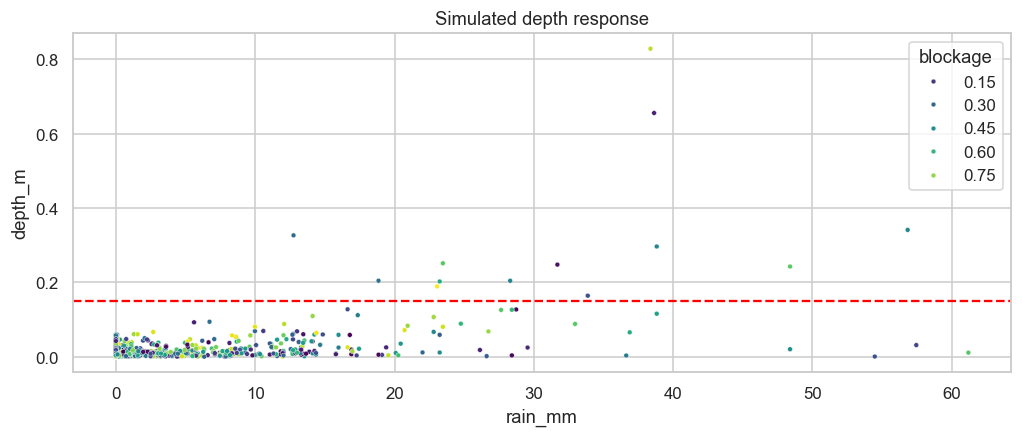

In [14]:
sns.scatterplot(data=eda.sample(min(2500,len(eda)),random_state=SEED),x='rain_mm',y='depth_m',hue='blockage',palette='viridis',s=10)
plt.axhline(.15,color='red',ls='--');plt.title('Simulated depth response');plt.show()

### 4.5 Correlation matrix

Depth and target appear only for diagnosis and are forbidden model features.

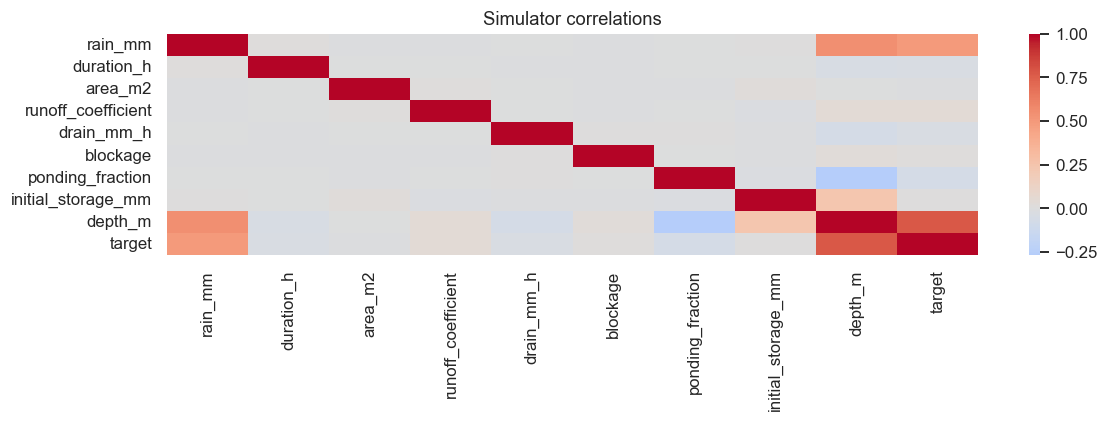

In [15]:
sns.heatmap(eda[FLOOD_FEATURES+['depth_m','target']].corr(),center=0,cmap='coolwarm');plt.title('Simulator correlations');plt.tight_layout();plt.show()

### 4.6 Temporal forcing coverage

Independent storms/days, not scenario row count, determine weather diversity.

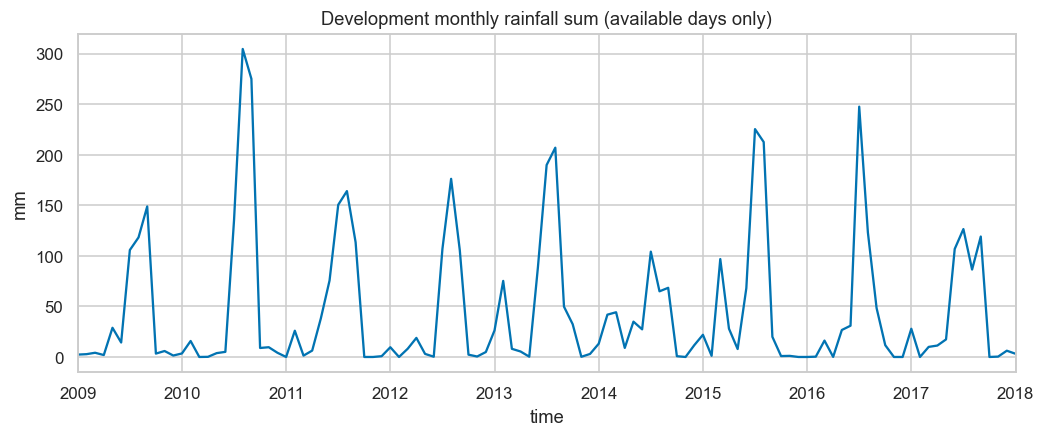

In [16]:
eda.drop_duplicates('event_id').set_index('time').rain_mm.resample('MS').sum().plot(title='Development monthly rainfall sum (available days only)',ylabel='mm');plt.show()

## 05. Preprocessing

Real rainfall uses the same exact-duplicate, negative-value and regular-grid policies as notebook 01. No future interpolation and no deletion of positive extremes. Synthetic inputs are finite by construction; a pipeline imputer is retained for consistent model infrastructure, while serving rejects missing physical inputs. Scaling is only used for Logistic Regression. No city-name join, geospatial interpolation or synthetic incident count is performed.

### 5.1 Physical range checks

Fail on impossible fractions rather than silently clipping them.

In [17]:
assert scenarios.rain_mm.ge(0).all()
assert scenarios.duration_h.between(1,12).all()
assert scenarios.blockage.between(0,.9).all()
assert scenarios.ponding_fraction.between(.03,.2).all()
assert scenarios.depth_m.ge(0).all()
print('PASS: simulator physical ranges')

PASS: simulator physical ranges


### 5.2 Unit and conservation check

Area cancels from depth but not volume. The end-of-event balance tracks rainfall runoff, drainage and remaining storage.

In [18]:
x=eda.head(1000)
initial=x.initial_storage_mm*x.area_m2/1000
runoff=x.rain_mm*x.runoff_coefficient*x.area_m2/1000
capacity=x.drain_mm_h*(1-x.blockage)*x.duration_h*x.area_m2/1000
outflow=np.minimum(initial+runoff,capacity)
final=np.maximum(0,initial+runoff-capacity)
np.testing.assert_allclose(initial+runoff,outflow+final,rtol=1e-12,atol=1e-8)
print('Maximum water-balance error (m³):',np.max(np.abs(initial+runoff-outflow-final)))

Maximum water-balance error (m³): 0.0


### 5.3 Labels and identifiers are excluded

Derived depth, storage and the exact threshold function would directly reveal the answer.

In [19]:
features=FLOOD_FEATURES.copy()
assert not {'depth_m','target','event_id','scenario_id','target_time'} & set(features)
display(pd.DataFrame({'feature':features}))

,feature
0,rain_mm
1,duration_h
2,area_m2
3,runoff_coefficient
4,drain_mm_h
5,blockage
6,ponding_fraction
7,initial_storage_mm


## 06. Feature engineering

Primary inputs are scenario forcing and physical design assumptions. Avoid adding the exact net-storage/depth formula as a predictor: that would trivialize label reconstruction. Area is retained as a negative-control variable; the specified physics predicts no direct area effect under proportional capacity. Model importance on area can reveal approximation artifacts. No incident-history, observed speed or measured water-level field is invented.

### 6.1 Illustrate sensitivity features without training on target algebra

Effective drainage and runoff are diagnostic quantities, excluded from the feature matrix.

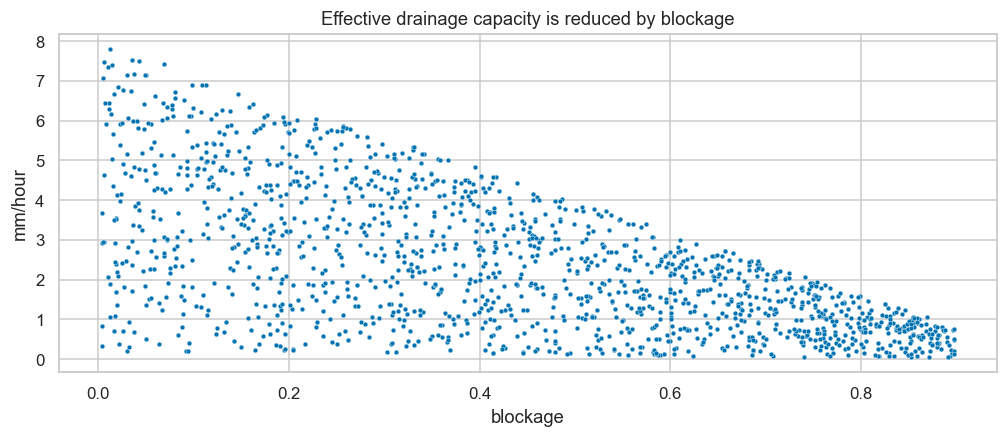

In [20]:
diagnostic=eda[['rain_mm','drain_mm_h','blockage']].copy()
diagnostic['effective_capacity']=diagnostic.drain_mm_h*(1-diagnostic.blockage)
sns.scatterplot(data=diagnostic.sample(min(1500,len(diagnostic)),random_state=SEED),x='blockage',y='effective_capacity',s=10)
plt.title('Effective drainage capacity is reduced by blockage');plt.ylabel('mm/hour');plt.show()

### 6.2 Demonstrate area invariance

Changing catchment area alone should not change depth in this deliberately simplified model.

In [21]:
a=eda[features].head(100).copy();b=a.copy();b['area_m2']*=2
np.testing.assert_allclose(simulate_depth(a),simulate_depth(b))
print('PASS: depth is invariant to area under proportional drainage capacity')

PASS: depth is invariant to area under proportional drainage capacity


### 6.3 Monotonic physical checks

Increasing rainfall or blockage cannot reduce depth under these equations.

In [22]:
a=eda[features].head(1000).copy()
b=a.copy();b.rain_mm+=20
c=a.copy();c.blockage=np.minimum(.99,c.blockage+.1)
assert (simulate_depth(b)>=simulate_depth(a)-1e-12).all()
assert (simulate_depth(c)>=simulate_depth(a)-1e-12).all()
print('PASS: rainfall and blockage monotonicity')

PASS: rainfall and blockage monotonicity


## 07. Training strategy

Split by unique real forcing date, then use expanding, purged temporal folds. All four scenarios from a date remain together. This tests transfer to later rainfall dates, not transfer to real assets or unseen physical laws. The middle 20% is further divided chronologically into probability-calibration and decision-threshold segments. Only development data is used for model selection. Class weights are learned/controlled inside each model fit; no global SMOTE is used.

### 7.1 Audit split and class balance

Every training and validation fold must contain both classes.

In [23]:
Xdev,ydev=dev[features],dev.target
Xtest,ytest=test[features],test.target
folds=temporal_folds(dev,N_SPLITS)
for tr,va in folds:
    assert dev.iloc[tr].target.nunique()==2 and dev.iloc[va].target.nunique()==2
for left,right in [(dev,cal),(cal,test)]:
    assert not set(left.event_id)&set(right.event_id)
    assert left.target_time.max()<right.time.min()
split_summary=pd.DataFrame([{'split':name,'rows':len(z),'forcing_dates':z.event_id.nunique(),'prevalence':z.target.mean(),'start':str(z.time.min()),'end':str(z.time.max())} for name,z in [('dev',dev),('cal',cal),('test',test)]])
display(split_summary);split_summary.to_csv(OUT/'splits.csv',index=False)

,split,rows,forcing_dates,prevalence,start,end
0,dev,13244,3311,0.006494,2009-01-01 00:00:00+05:30,2018-01-24 00:00:00+05:30
1,cal,4412,1103,0.006120,2018-01-26 00:00:00+05:30,2021-02-19 00:00:00+05:30
2,test,4420,1105,0.011312,2021-02-21 00:00:00+05:30,2024-03-20 00:00:00+05:30


### 7.2 Models and fold-local preprocessing

Compare prior probability, standard Logistic Regression, balanced Logistic Regression and XGBoost. PR-AUC is the selection metric because simulated floods are rare.

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (average_precision_score,roc_auc_score,brier_score_loss,classification_report,ConfusionMatrixDisplay,PrecisionRecallDisplay,RocCurveDisplay,f1_score,precision_score,recall_score)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

def clf_pipeline(model,scale=False):
    steps=[('impute',SimpleImputer(strategy='median',keep_empty_features=True))]
    if scale: steps.append(('scale',StandardScaler()))
    return Pipeline(steps+[('model',model)])
models={
 'Prior':clf_pipeline(DummyClassifier(strategy='prior')),
 'Logistic':clf_pipeline(LogisticRegression(max_iter=3000,random_state=SEED),True),
 'Logistic balanced':clf_pipeline(LogisticRegression(class_weight='balanced',max_iter=3000,random_state=SEED),True),
 'XGBoost':clf_pipeline(XGBClassifier(n_estimators=120,max_depth=3,learning_rate=.05,eval_metric='logloss',tree_method='hist',n_jobs=2,random_state=SEED))}

## 08. Model experiments

The deterministic simulator itself has perfect agreement with its labels by definition. The learned models only approximate this mapping. Their CV scores cannot demonstrate real-world flood validity.

### 8.1 Compare models on temporal folds

Report average precision and ROC-AUC, plus calibration-sensitive Brier loss.

In [25]:
cv_rows=[]
for name,model in models.items():
    scores=cross_validate(model,Xdev,ydev,cv=folds,scoring={'ap':'average_precision','auc':'roc_auc','brier':'neg_brier_score'},error_score='raise',n_jobs=1)
    for i in range(N_SPLITS):
        cv_rows.append({'model':name,'fold':i,'AP':scores['test_ap'][i],'ROC_AUC':scores['test_auc'][i],'Brier':-scores['test_brier'][i]})
cv_details=pd.DataFrame(cv_rows)
summary=cv_details.groupby('model').agg(AP=('AP','mean'),AP_std=('AP','std'),ROC_AUC=('ROC_AUC','mean'),Brier=('Brier','mean')).sort_values('AP',ascending=False)
display(summary);cv_details.to_csv(OUT/'candidate_cv.csv',index=False)

,AP,AP_std,ROC_AUC,Brier
model,,,,
XGBoost,0.866432,0.031524,0.998281,0.002186
Logistic,0.854020,0.093386,0.998759,0.002131
Logistic balanced,0.835282,0.119566,0.998868,0.006781
Prior,0.006046,0.001600,0.500000,0.006012


### 8.2 Visualize discrimination and calibration

Balanced weighting can improve recall while distorting raw probability calibration.

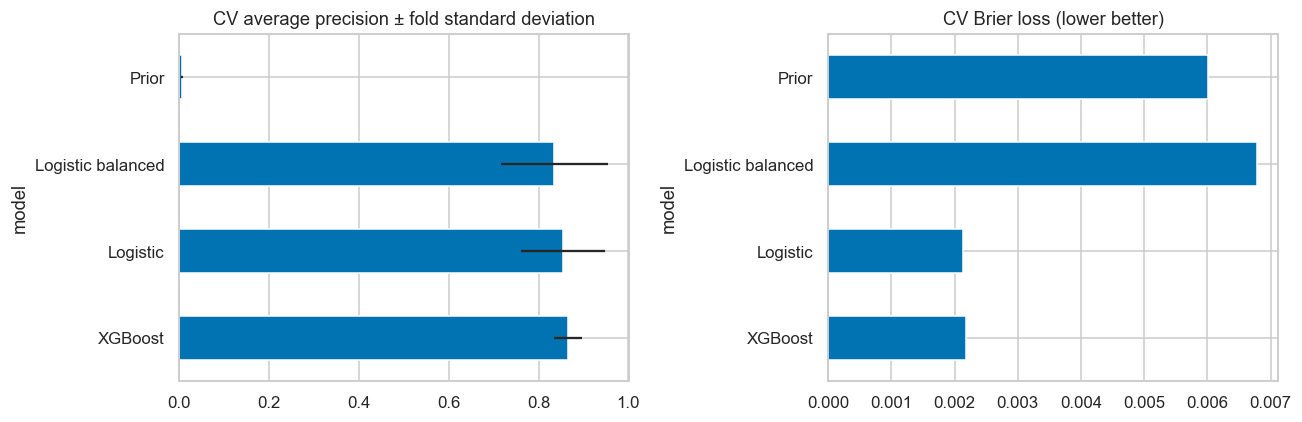

In [26]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
summary.AP.plot.barh(xerr=summary.AP_std,ax=ax[0],title='CV average precision ± fold standard deviation')
summary.Brier.plot.barh(ax=ax[1],title='CV Brier loss (lower better)');plt.tight_layout();plt.show()

## 09. Hyperparameter tuning

Tune both primary families: Logistic Regression (including weighting) and XGBoost. Keep the same grouped temporal folds. Use two distinct later calibration blocks so probability calibration and action-threshold choice do not share labels.

### 9.1 Search spaces

No test-label class ratio or test-period early stopping is used.

In [27]:
spaces={'Logistic':{'model__C':[.01,.1,1,10,100],'model__class_weight':[None,'balanced']},'XGBoost':{'model__n_estimators':[80,140,220],'model__max_depth':[2,3,5],'model__learning_rate':[.03,.08,.15],'model__min_child_weight':[1,5,10],'model__scale_pos_weight':[1,3,10],'model__reg_lambda':[1,5,10]}}
searches={}
selection={name:float(summary.loc[name,'AP']) for name in models}
for name,space in spaces.items():
    s=RandomizedSearchCV(models[name],space,n_iter=N_SEARCH,scoring='average_precision',cv=folds,random_state=SEED,n_jobs=1,error_score='raise',return_train_score=True)
    s.fit(Xdev,ydev);searches[name]=s;selection[name+' tuned']=s.best_score_
    trials=pd.DataFrame(s.cv_results_);trials.to_csv(OUT/(name+'_search.csv'),index=False)
    display(trials.sort_values('rank_test_score')[['mean_test_score','std_test_score','params']].head())
selected_name=max(selection,key=selection.get)
final_model=searches[selected_name.removesuffix(' tuned')].best_estimator_ if selected_name.endswith(' tuned') else clone(models[selected_name]).fit(Xdev,ydev)
print('Locked winner:',selected_name)

,mean_test_score,std_test_score,params
4,0.842891,0.094507,"{'model__class_weight': 'balanced', 'model__C'..."
2,0.835282,0.097625,"{'model__class_weight': 'balanced', 'model__C'..."
0,0.835116,0.076369,"{'model__class_weight': None, 'model__C': 100}"
5,0.782657,0.076160,"{'model__class_weight': None, 'model__C': 0.1}"
1,0.634225,0.041340,"{'model__class_weight': 'balanced', 'model__C'..."


,mean_test_score,std_test_score,params
5,0.872948,0.034597,"{'model__scale_pos_weight': 3, 'model__reg_lam..."
2,0.830256,0.040195,"{'model__scale_pos_weight': 1, 'model__reg_lam..."
3,0.814108,0.064564,"{'model__scale_pos_weight': 3, 'model__reg_lam..."
0,0.812163,0.053603,"{'model__scale_pos_weight': 1, 'model__reg_lam..."
1,0.811073,0.071387,"{'model__scale_pos_weight': 1, 'model__reg_lam..."


Locked winner: XGBoost tuned


### 9.2 Tuning comparison plot

Selection scores are development estimates, not final performance.

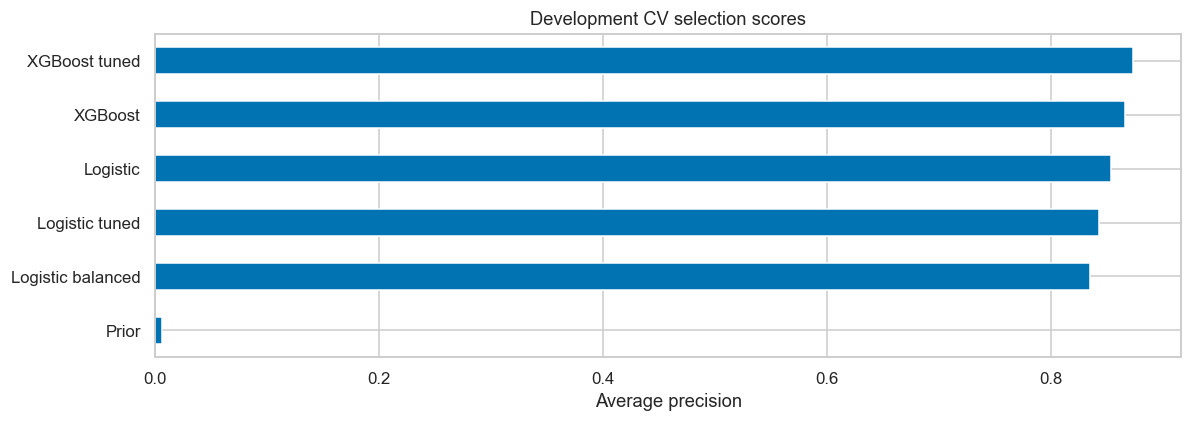

In [28]:
pd.Series(selection).sort_values().plot.barh(title='Development CV selection scores',xlabel='Average precision');plt.tight_layout();plt.show()

### 9.3 Probability calibration

Isotonic calibration maps raw probabilities on the earlier half of the calibration dates. If there are too few positives, stop and enlarge the study rather than silently reporting invalid calibration.

In [29]:
cal_times=np.sort(cal.time.unique());boundary=cal_times[len(cal_times)//2]
prob_cal=cal[(cal.time<boundary)&(cal.target_time<boundary)].copy()
threshold_cal=cal[cal.time>=boundary].copy()
assert prob_cal.target.sum()>=10 and threshold_cal.target.sum()>=10
assert prob_cal.target.nunique()==2 and threshold_cal.target.nunique()==2
calibrator=IsotonicRegression(out_of_bounds='clip')
calibrator.fit(final_model.predict_proba(prob_cal[features])[:,1],prob_cal.target)
p_threshold=calibrator.predict(final_model.predict_proba(threshold_cal[features])[:,1])

### 9.4 Choose an explicit decision threshold

Illustrative false-negative cost is five times false-positive cost. This project utility assumption requires stakeholder validation; it is not an emergency policy.

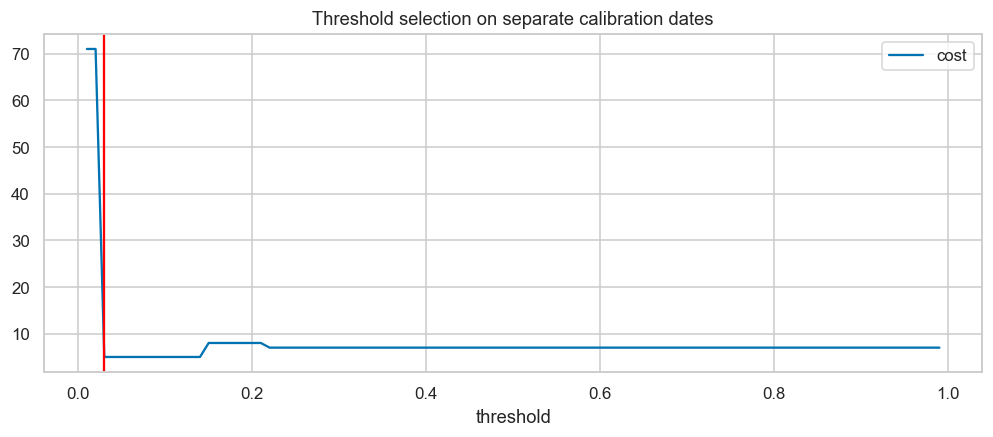

Locked threshold: 0.03


In [30]:
threshold_rows=[]
for threshold in np.linspace(.01,.99,99):
    yhat=p_threshold>=threshold
    fn=int(((threshold_cal.target==1)&~yhat).sum())
    fp=int(((threshold_cal.target==0)&yhat).sum())
    threshold_rows.append({'threshold':threshold,'cost':5*fn+fp,'FN':fn,'FP':fp})
threshold_table=pd.DataFrame(threshold_rows)
threshold=float(threshold_table.sort_values(['cost','threshold']).iloc[0].threshold)
threshold_table.plot(x='threshold',y='cost',title='Threshold selection on separate calibration dates');plt.axvline(threshold,color='red');plt.show()
print('Locked threshold:',threshold)
threshold_table.to_csv(OUT/'threshold_search.csv',index=False)

## 10. Final evaluation

Evaluate discrimination, calibration, decision errors, rainfall regimes and physical sensitivities. All labels remain synthetic. Accuracy alone would conceal rare-event failures.

### 10.1 Final metrics and confusion matrix

The model, calibrator and threshold are frozen before this cell.

average_precision      0.897110
ROC_AUC                0.998908
Brier_raw              0.002063
Brier_calibrated       0.002423
F1                     0.784000
precision              0.653333
recall                 0.980000
threshold              0.030000
positive_prevalence    0.011312
dtype: float64

              precision    recall  f1-score   support

           0       1.00      0.99      1.00      4370
           1       0.65      0.98      0.78        50

    accuracy                           0.99      4420
   macro avg       0.83      0.99      0.89      4420
weighted avg       1.00      0.99      0.99      4420



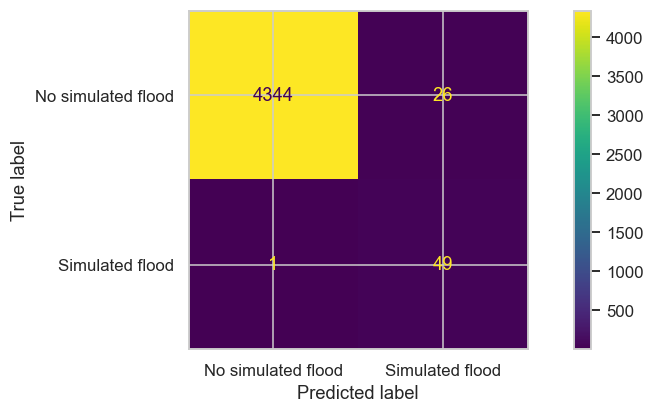

In [31]:
p_raw=final_model.predict_proba(Xtest)[:,1]
p=calibrator.predict(p_raw)
yhat=p>=threshold
metrics={'average_precision':float(average_precision_score(ytest,p)),'ROC_AUC':float(roc_auc_score(ytest,p)),'Brier_raw':float(brier_score_loss(ytest,p_raw)),'Brier_calibrated':float(brier_score_loss(ytest,p)),'F1':float(f1_score(ytest,yhat)),'precision':float(precision_score(ytest,yhat,zero_division=0)),'recall':float(recall_score(ytest,yhat)),'threshold':threshold,'positive_prevalence':float(ytest.mean())}
display(pd.Series(metrics));print(classification_report(ytest,yhat,zero_division=0))
ConfusionMatrixDisplay.from_predictions(ytest,yhat,display_labels=['No simulated flood','Simulated flood']);plt.show()

### 10.2 Precision-recall and ROC curves

PR baseline equals test prevalence; a strong ROC score can coexist with poor rare-event precision.

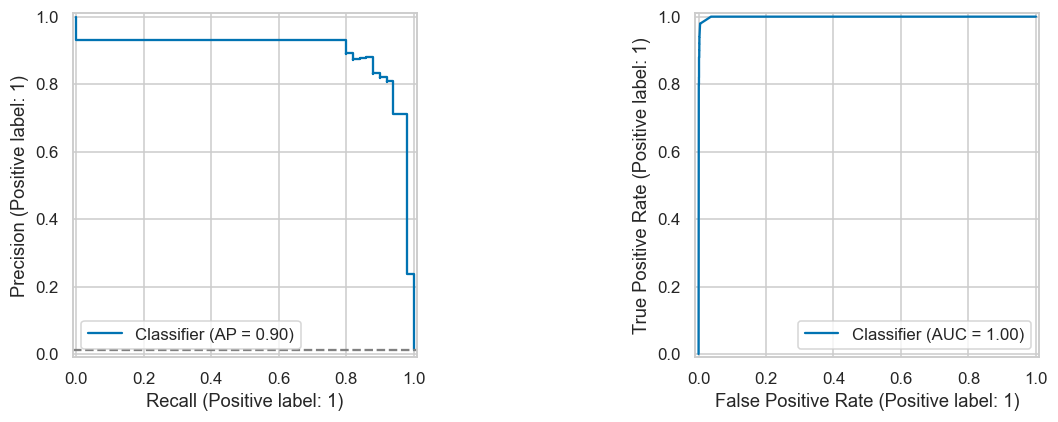

In [32]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
PrecisionRecallDisplay.from_predictions(ytest,p,ax=ax[0]);ax[0].axhline(ytest.mean(),ls='--',color='grey')
RocCurveDisplay.from_predictions(ytest,p,ax=ax[1]);plt.tight_layout();plt.show()

### 10.3 Probability reliability

Compare raw and calibrated probabilities; calibration can worsen under temporal or simulator shift.

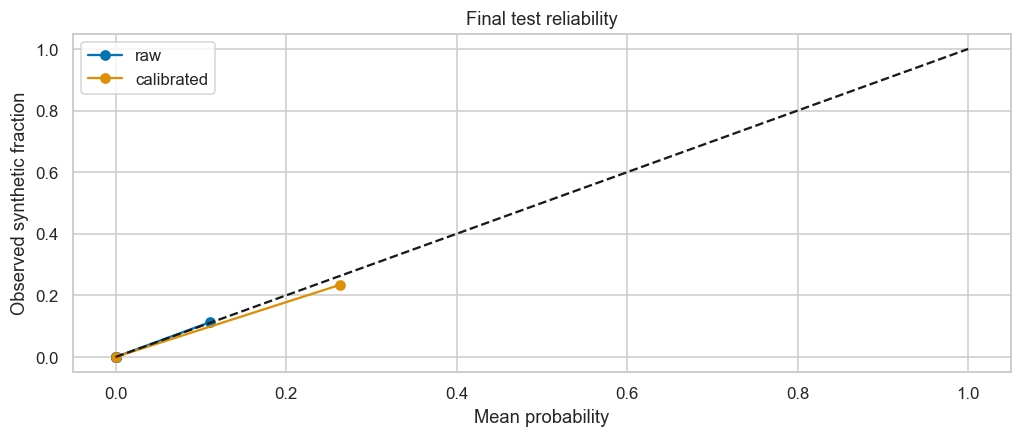

In [33]:
for label,probs in [('raw',p_raw),('calibrated',p)]:
    observed,mean=calibration_curve(ytest,probs,n_bins=10,strategy='quantile')
    plt.plot(mean,observed,marker='o',label=label)
plt.plot([0,1],[0,1],'k--');plt.legend();plt.xlabel('Mean probability');plt.ylabel('Observed synthetic fraction');plt.title('Final test reliability');plt.show()

### 10.4 Error analysis and exportable examples

False negatives can cluster near the assumed 0.15 m threshold.

In [34]:
errors=test.copy();errors['probability']=p;errors['predicted']=yhat;errors['wrong']=yhat!=ytest
errors['rain_bin']=pd.cut(errors.rain_mm,[-.01,1,10,30,100,np.inf])
display(errors.groupby('rain_bin',observed=True).agg(n=('target','size'),positives=('target','sum'),error_rate=('wrong','mean')))
display(errors[errors.wrong].sort_values('depth_m',ascending=False).head(12))
errors.to_csv(OUT/'test_predictions.csv',index=False)

,n,positives,error_rate
rain_bin,,,
"(-0.01, 1.0]",3612,0,0.000000
"(1.0, 10.0]",552,0,0.000000
"(10.0, 30.0]",168,8,0.089286
"(30.0, 100.0]",88,42,0.136364


,time,rain_mm,event_id,scenario_id,duration_h,area_m2,runoff_coefficient,drain_mm_h,blockage,ponding_fraction,initial_storage_mm,depth_m,target,target_time,source_quality,probability,predicted,wrong,rain_bin
683,2021-08-21 00:00:00+05:30,97.50,2021-08-21 00:00:00+05:30,18347,9.087488,54450.737740,0.478870,5.488001,0.500571,0.097113,0.973060,0.234317,1,2021-08-22 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...,0.025974,False,True,"(30.0, 100.0]"
1995,2022-07-21 00:00:00+05:30,30.09,2022-07-21 00:00:00+05:30,19659,2.244601,81394.724136,0.792501,1.750442,0.027284,0.152196,1.946608,0.144361,0,2022-07-22 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...,0.101309,True,True,"(30.0, 100.0]"
2311,2022-10-08 00:00:00+05:30,13.10,2022-10-08 00:00:00+05:30,19975,4.966097,19966.635521,0.947142,3.155259,0.709041,0.065606,1.621055,0.144339,0,2022-10-09 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...,0.340492,True,True,"(10.0, 30.0]"
3363,2023-06-30 00:00:00+05:30,16.80,2023-06-30 00:00:00+05:30,21027,7.103200,32276.620981,0.552700,1.995377,0.873914,0.064508,1.698896,0.142575,0,2023-07-01 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...,0.142857,True,True,"(10.0, 30.0]"
1766,2022-05-23 00:00:00+05:30,26.13,2022-05-23 00:00:00+05:30,19430,4.725537,48929.056851,0.781539,2.576244,0.508073,0.104969,0.511474,0.142369,0,2022-05-24 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...,0.092182,True,True,"(10.0, 30.0]"
1920,2022-07-01 00:00:00+05:30,61.71,2022-07-01 00:00:00+05:30,19584,4.256331,98511.172453,0.605675,3.624860,0.131256,0.177265,0.905080,0.140342,0,2022-07-02 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...,0.334512,True,True,"(30.0, 100.0]"
2315,2022-10-09 00:00:00+05:30,67.46,2022-10-09 00:00:00+05:30,19979,4.697746,66465.254374,0.553343,6.753829,0.318093,0.123765,1.400239,0.138112,0,2022-10-10 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...,0.142857,True,True,"(30.0, 100.0]"
727,2021-09-01 00:00:00+05:30,72.81,2021-09-01 00:00:00+05:30,18391,3.558082,33810.062282,0.319756,0.653883,0.160703,0.167321,1.262184,0.135016,0,2021-09-02 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...,1.000000,True,True,"(30.0, 100.0]"
914,2021-10-18 00:00:00+05:30,53.08,2021-10-18 00:00:00+05:30,18578,11.012872,52674.793577,0.773843,6.379804,0.643519,0.134981,1.865091,0.132569,0,2021-10-19 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...,0.142857,True,True,"(30.0, 100.0]"
2256,2022-09-25 00:00:00+05:30,18.42,2022-09-25 00:00:00+05:30,19920,1.810604,74343.147488,0.600810,3.044950,0.012101,0.052137,1.018986,0.127346,0,2022-09-26 00:00:00+05:30,synthetic uncalibrated drainage; real state-le...,1.000000,True,True,"(10.0, 30.0]"


### 10.5 Check sensitivity outside sampled conditions

These are labeled stress scenarios, not new real test observations. A classifier can violate physics even if its average score is high.

In [35]:
stress=Xtest.head(1000).copy();stress['rain_mm']*=1.5;stress['blockage']=np.minimum(.99,stress.blockage+.1)
stress_truth=(simulate_depth(stress)>=.15).astype(int)
stress_p=calibrator.predict(final_model.predict_proba(stress)[:,1])
print('Shifted synthetic scenario recall:',recall_score(stress_truth,stress_p>=threshold,zero_division=0))
print('Fraction with decreasing probability despite increased forcing:',np.mean(stress_p<p[:len(stress)]-1e-9))

Shifted synthetic scenario recall: 0.9047619047619048
Fraction with decreasing probability despite increased forcing: 0.0


## 11. Explainability

Importance reflects simulator emulation. It does not discover real hydrological causes. Features such as area should have negligible true effect under the stated equations; nonzero model attribution indicates approximation or correlation artifacts.

### 11.1 Permutation importance

Calibration dates are used for explanation; no feature reselection follows.

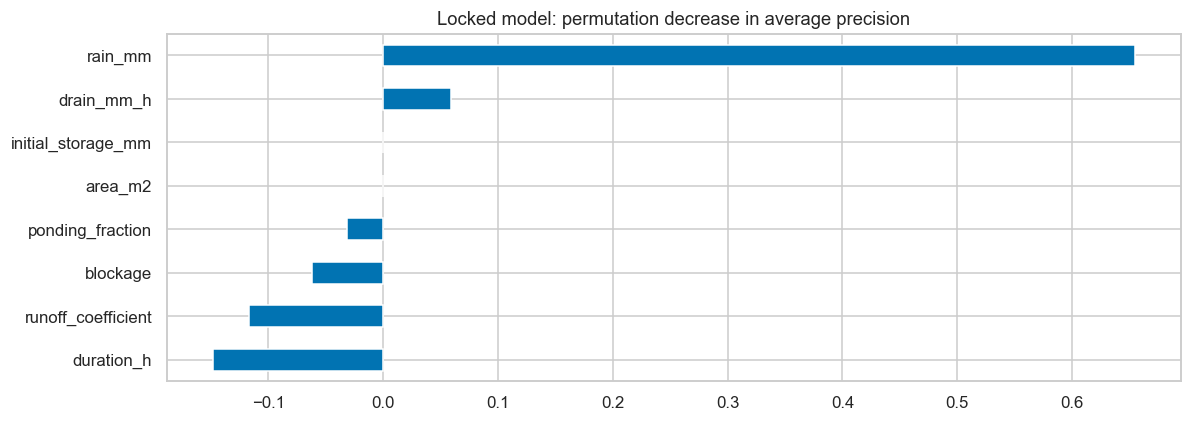

In [36]:
explain_X=threshold_cal[features].sample(min(300,len(threshold_cal)),random_state=SEED)
explain_y=threshold_cal.target.loc[explain_X.index]
pi=permutation_importance(final_model,explain_X,explain_y,scoring='average_precision',n_repeats=4,random_state=SEED)
importance=pd.Series(pi.importances_mean,index=features).sort_values()
importance.plot.barh(title='Locked model: permutation decrease in average precision');plt.tight_layout();plt.show()
importance.to_csv(OUT/'permutation_importance.csv')

### 11.2 SHAP global explanation

SHAP explains the underlying fitted XGBoost margin, before isotonic calibration. If Logistic wins, this plot is explicitly an auxiliary XGBoost explanation.

Explaining XGBoost tuned raw margin, not calibrated probability


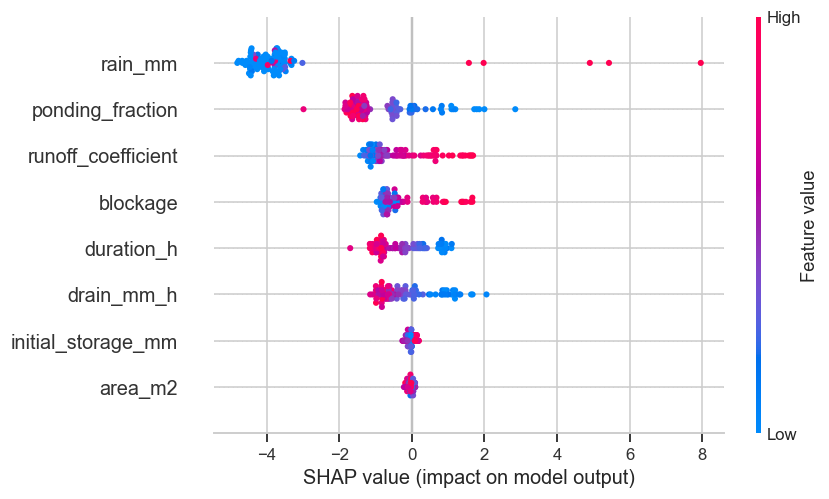

In [37]:
import shap
if isinstance(final_model.named_steps['model'],XGBClassifier):
    shap_model=final_model;shap_label=selected_name
else:
    shap_model=searches['XGBoost'].best_estimator_;shap_label='Auxiliary XGBoost, not selected model'
transformed=shap_model[:-1].transform(explain_X.iloc[:100])
explanation=shap.TreeExplainer(shap_model.named_steps['model'])(transformed)
explanation.feature_names=features
print('Explaining',shap_label,'raw margin, not calibrated probability')
shap.plots.beeswarm(explanation,show=False);plt.tight_layout();plt.show()

### 11.3 Individual explanation

Show the physical inputs next to the raw-model explanation.

,rain_mm,duration_h,area_m2,runoff_coefficient,drain_mm_h,blockage,ponding_fraction,initial_storage_mm
4261,0.0,2.003887,85780.776869,0.514167,5.268446,0.049929,0.156452,0.703049


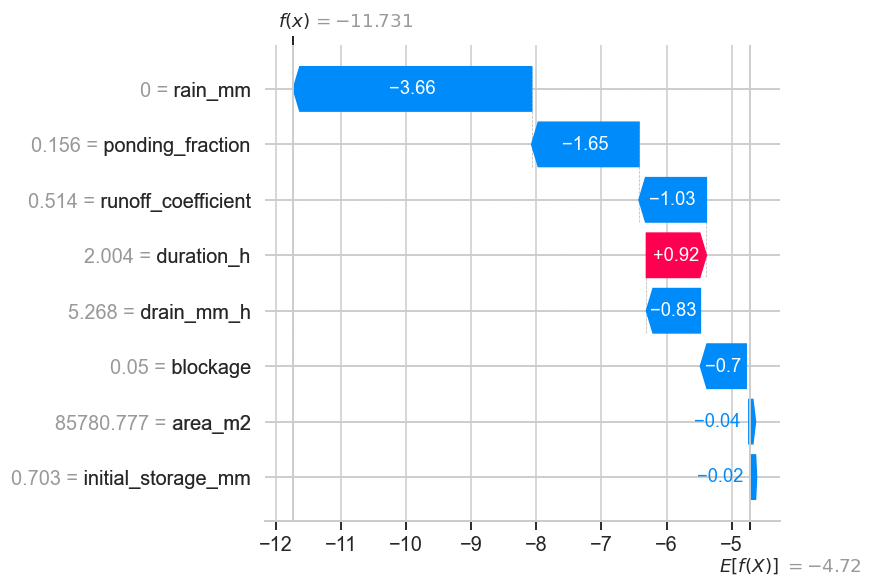

In [38]:
display(explain_X.iloc[[0]])
shap.plots.waterfall(explanation[0],show=False);plt.tight_layout();plt.show()

## 12. Model export

Export the input pipeline, probability calibrator, threshold, schema, simulator assumptions and source checksum. Serving accepts only supplied scenario inputs; it never pretends to know tomorrow’s actual rain.

### 12.1 Save reproducible artifacts

A versioned module holds the bundle class so joblib does not rely on notebook-local definitions.

In [39]:
metadata={'task':'synthetic flood scenario classification','winner':selected_name,'seed':SEED,'rain_sha256':fingerprint,'scenario_count':len(scenarios),'forcing_dates':scenarios.event_id.nunique(),'synthetic':True,'label':'simulated peak depth >= 0.15 m','scenario_horizon':'24 hours; uniform storm duration 1–12 h','spatial_support':'Delhi state rainfall reference, hypothetical catchments','physics':'lumped mass balance, uncalibrated','metrics':metrics,'deployment_status':'research scenario surrogate; not validated real flood or infrastructure failure forecast','versions':{name:importlib.metadata.version(name) for name in ['numpy','pandas','scikit-learn','xgboost','shap']}}
bundle=FloodBundle(final_model,calibrator,threshold,metadata)
joblib.dump(bundle,OUT/'pipeline.joblib')
(OUT/'metadata.json').write_text(json.dumps(metadata,indent=2,default=str))
(OUT/'feature_schema.json').write_text(parameter_table.to_json(orient='records',indent=2))
(OUT/'metrics.json').write_text(json.dumps(metrics,indent=2))

295

### 12.2 Serialization round-trip

Verify that the saved artifact accepts scenario inputs and reproduces probabilities.

In [40]:
loaded=joblib.load(OUT/'pipeline.joblib')
example=Xtest.iloc[[0]].copy()
pd.testing.assert_frame_equal(loaded.predict(example),bundle.predict(example))
display(loaded.predict(example));print('PASS: flood bundle round-trip')

,simulated_flood_probability,scenario_alert,synthetic
0,0.0,False,True


PASS: flood bundle round-trip


## 13. CivicFlux integration

Use a scenario envelope to request an engineering review. A rainfall forecast interval is uncertainty about state-scale rainfall, not automatically the local storm forcing. The illustrative range below is user-supplied hypothetical rainfall. No unrelated AQI/traffic location is joined. No automatic evacuation, dispatch, road closure or risk claim is made.

### 13.1 Scenario envelope from uncertain rainfall input

Evaluate low, central and high supplied rain values independently. The probability range is not a calibrated joint flood forecast interval.

,simulated_flood_probability,scenario_alert,synthetic,supplied_rain_mm
0,0.000000,False,True,10
1,0.025974,False,True,30
2,1.000000,True,True,70


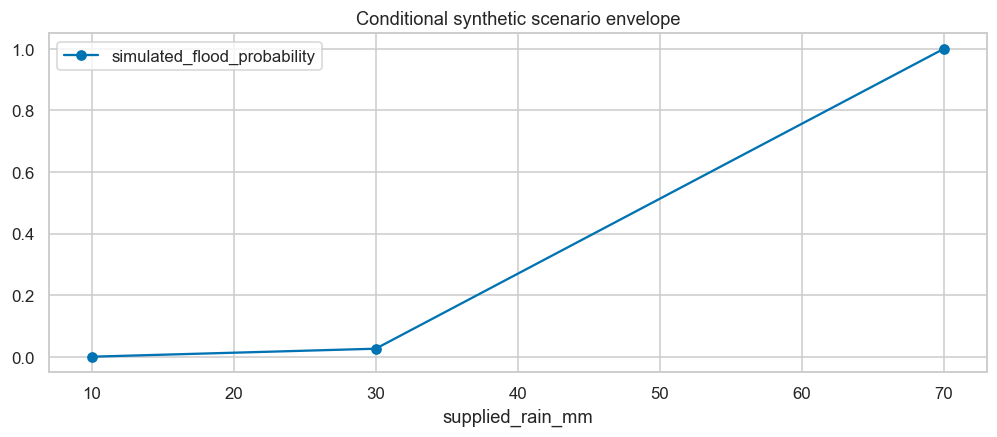

In [41]:
scenario_inputs=pd.concat([example]*3,ignore_index=True)
scenario_inputs['rain_mm']=[10,30,70]  # Hypothetical low/central/high storm totals.
scenario_results=loaded.predict(scenario_inputs)
scenario_results['supplied_rain_mm']=scenario_inputs.rain_mm
display(scenario_results)
scenario_results.plot(x='supplied_rain_mm',y='simulated_flood_probability',marker='o',title='Conditional synthetic scenario envelope');plt.show()

### 13.2 Decision-engine payload

Carry the synthetic flag and physical assumptions into every consumer.

In [42]:
payload={'variable':'simulated_flood_scenario_probability','synthetic':True,'geography':'hypothetical catchment; Delhi state rainfall reference only','horizon_hours':24,'rain_scenarios_mm':[10,30,70],'probabilities':scenario_results.simulated_flood_probability.tolist(),'decision_threshold':threshold,'action':'engineering_review' if scenario_results.scenario_alert.any() else 'retain_for_scenario_planning','automatic_dispatch':False,'limitations':['uncalibrated drainage','no real incident labels','daily state rainfall is not local storm intensity','no infrastructure-failure labels']}
print(json.dumps(payload,indent=2))
(OUT/'civicflux_payload.json').write_text(json.dumps(payload,indent=2))

{
  "variable": "simulated_flood_scenario_probability",
  "synthetic": true,
  "geography": "hypothetical catchment; Delhi state rainfall reference only",
  "horizon_hours": 24,
  "rain_scenarios_mm": [
    10,
    30,
    70
  ],
  "probabilities": [
    0.0,
    0.025974025949835777,
    1.0
  ],
  "decision_threshold": 0.03,
  "action": "engineering_review",
  "automatic_dispatch": false,
  "limitations": [
    "uncalibrated drainage",
    "no real incident labels",
    "daily state rainfall is not local storm intensity",
    "no infrastructure-failure labels"
  ]
}


575

### 13.3 Research conclusion

A high score means successful emulation of this simulator over later forcing dates. It does not validate local rainfall, hydrodynamics, observed floods or engineering design. Before real incident prediction, acquire measured local rainfall and water levels, dated flood incidents, drainage geometry and maintenance records, calibrate/validate the physical model against observed events, and hold out catchments as well as time. Changing parameter ranges or the depth threshold defines a new synthetic population and requires repeating the full study.